# Auto Evaluate — Used Car Price Prediction


**Presented by:**

Devika Gadge - 47

Laghima Kejriwal - 34

Pradyun Khot - 59

**Section:** A4
### Objective
Understand the used-car dataset, clean obvious data problems, and explore how car features relate to price. The notebook is split into small steps so each operation is easy to follow.

**Target column:** `Price`  
**Dataset file:** `Car_Raw_Data.csv`



## Part 1: Data Understanding, Cleaning and EDA

## Step 1 — Import the libraries

Pandas is used for tables, NumPy for numeric operations, and Matplotlib/Seaborn for graphs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Scikit-learn tools for training and evaluating models
import time
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## Step 2 — Load `Car_Raw_Data.csv`

Upload `Car_Raw_Data.csv` to the Colab session using the Files panel on the left, then run this cell.



In [2]:
df = pd.read_csv("Car_Raw_Data.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## Step 3 — View the first and last rows

This helps us understand what one record looks like and whether the file was read correctly.

In [3]:
display(df.head())
display(df.tail())

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
4340,Mercedes-Benz,125000.0,sedan,9,3.0,Diesel,yes,2014,S 350
4341,BMW,6500.0,sedan,1,3.5,Petrol,yes,1999,535
4342,BMW,8000.0,sedan,194,2.0,Petrol,yes,1985,520
4343,Toyota,14200.0,sedan,31,NaN,Petrol,yes,2014,Corolla
4344,Volkswagen,13500.0,van,124,2.0,Diesel,yes,2013,T5 (Transporter)


## Step 4 — Check dataset size, column names and data types

In [4]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

Rows and columns: (4345, 9)

Column names:
['Brand', 'Price', 'Body', 'Mileage', 'EngineV', 'Engine Type', 'Registration', 'Year', 'Model']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4345 entries, 0 to 4344
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         4345 non-null   object 
 1   Price         4173 non-null   float64
 2   Body          4345 non-null   object 
 3   Mileage       4345 non-null   int64  
 4   EngineV       4195 non-null   float64
 5   Engine Type   4345 non-null   object 
 6   Registration  4345 non-null   object 
 7   Year          4345 non-null   int64  
 8   Model         4345 non-null   object 
dtypes: float64(2), int64(2), object(5)
memory usage: 305.6+ KB


## Step 5 — Check missing values and duplicate rows

We inspect these before deciding how to clean the data.

In [5]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Number of duplicate rows:", df.duplicated().sum())

Missing values in each column:


,Missing values
Brand,0
Price,172
Body,0
Mileage,0
EngineV,150
Engine Type,0
Registration,0
Year,0
Model,0


Number of duplicate rows: 73


## Step 6 — Summary statistics

For numeric columns, describe() shows the count, average, spread and range. For text columns, it shows common categories.

In [6]:
display(df.describe().T)
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Price,4173.0,19418.746935,25584.242620,600.0,6999.0,11500.0,21700.0,300000.00
Mileage,4345.0,161.237284,105.705797,0.0,86.0,155.0,230.0,980.00
EngineV,4195.0,2.790734,5.066437,0.6,1.8,2.2,3.0,99.99
Year,4345.0,2006.550058,6.719097,1969.0,2003.0,2008.0,2012.0,2016.00


,count,unique,top,freq
Brand,4345,7,Volkswagen,936
Body,4345,6,sedan,1649
Engine Type,4345,4,Diesel,2019
Registration,4345,2,yes,3947
Model,4345,312,E-Class,199


## Step 7 — Check the target column (`Price`)

Price must be numeric and cannot be missing for supervised training. We will also check for zero or negative prices.

In [7]:
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
print("Missing prices:", df["Price"].isnull().sum())
print("Prices less than or equal to zero:", (df["Price"] <= 0).sum())
display(df["Price"].describe())

Missing prices: 172
Prices less than or equal to zero: 0


,Price
count,4173.000000
mean,19418.746935
std,25584.242620
min,600.000000
25%,6999.000000
50%,11500.000000
75%,21700.000000
max,300000.000000


## Step 8 — Plot the price distribution

The distribution helps us see whether most cars are in a lower price range and whether there is a long tail of expensive cars.

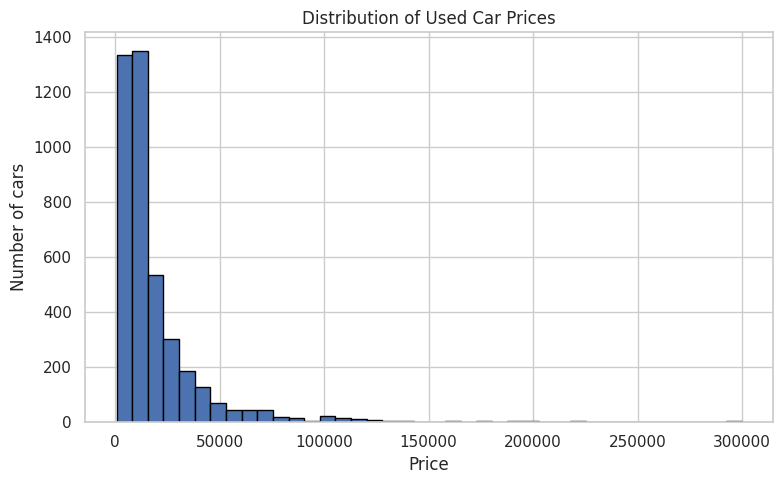

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["Price"].dropna(), bins=40, edgecolor="black")
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

## Step 9 — Explore numeric features

We plot mileage, engine volume and year to look for unusual values and understand their distributions.

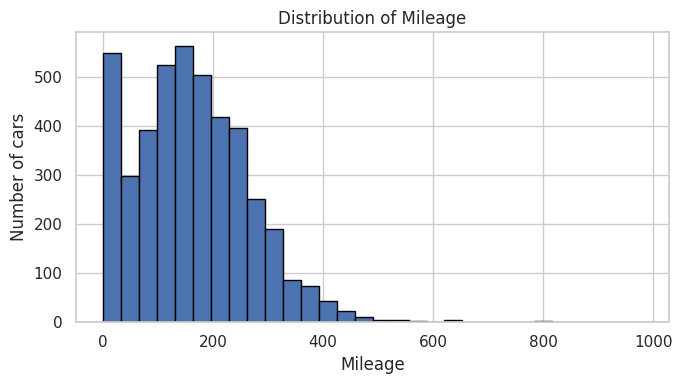

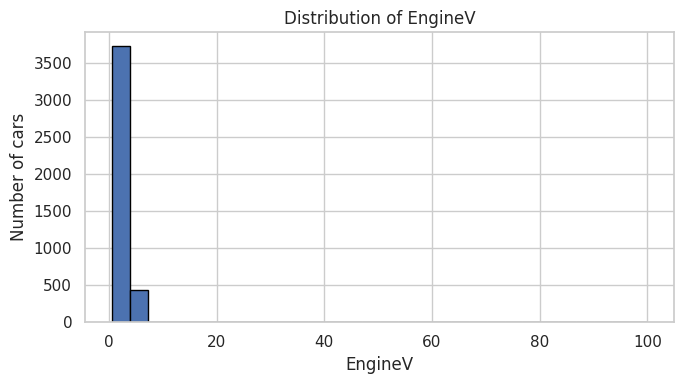

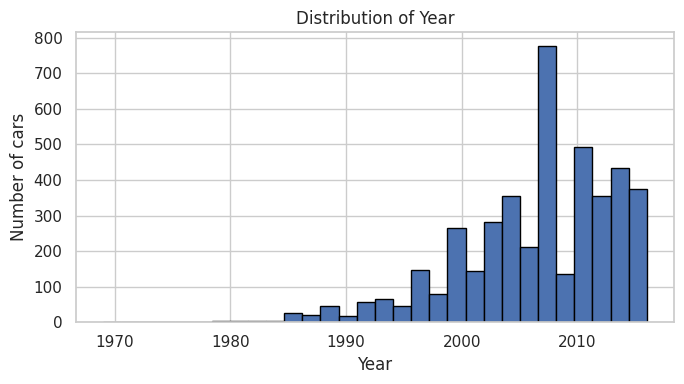

In [9]:
numeric_columns = ["Mileage", "EngineV", "Year"]

for column in numeric_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(df[column].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of cars")
    plt.tight_layout()
    plt.show()

## Step 10 — Explore categorical features

These bar charts show the most common brands, body styles, engine types and registration values.

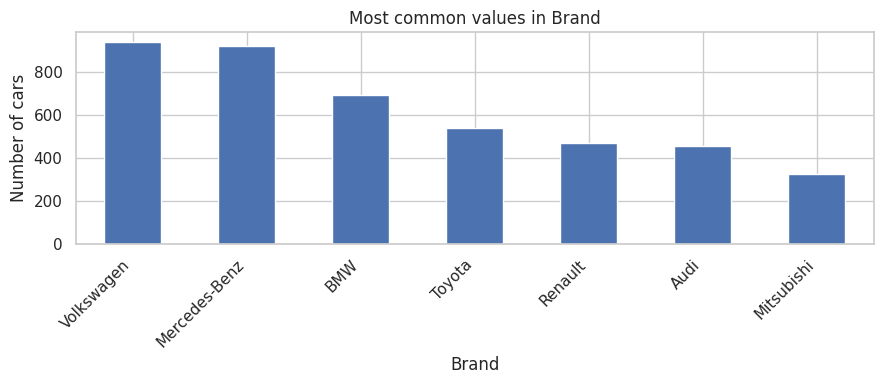

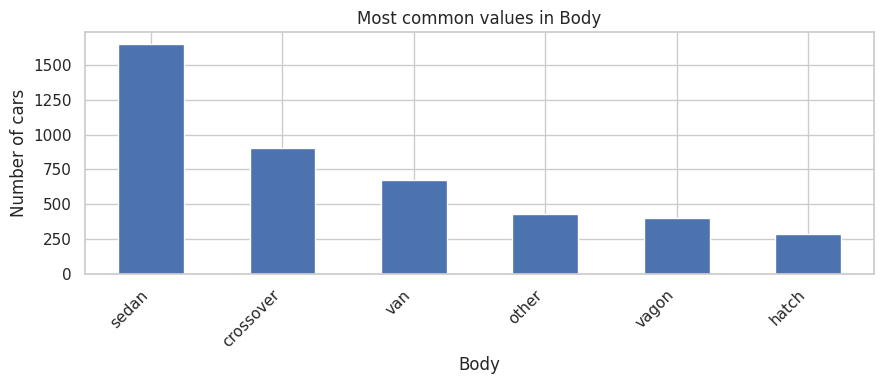

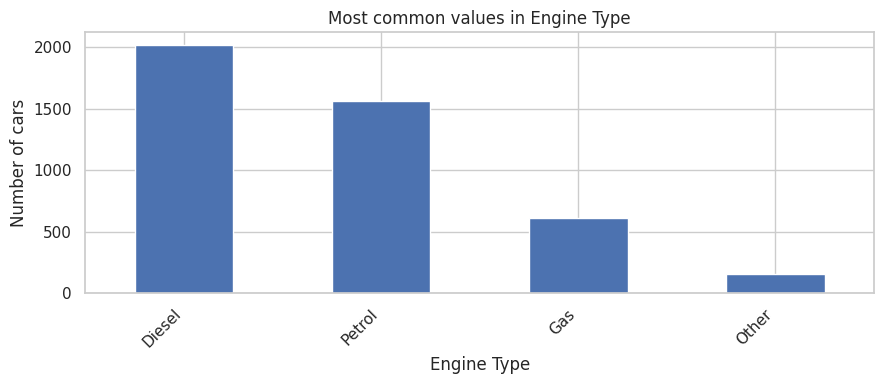

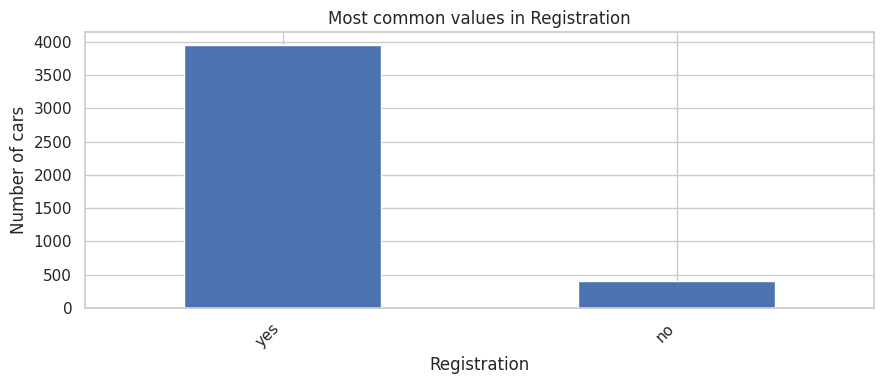

In [10]:
categorical_columns = ["Brand", "Body", "Engine Type", "Registration"]

for column in categorical_columns:
    plt.figure(figsize=(9, 4))
    df[column].value_counts().head(12).plot(kind="bar")
    plt.title(f"Most common values in {column}")
    plt.xlabel(column)
    plt.ylabel("Number of cars")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## Step 11 — Check numeric correlations

Correlation measures the strength of a linear relationship between numeric columns. It does not prove that one feature causes a change in price.

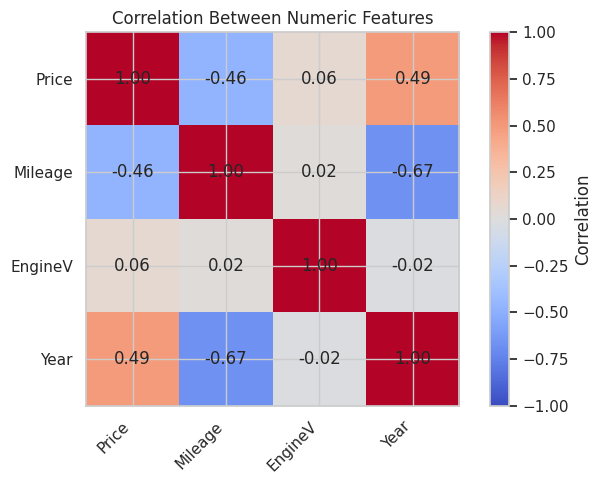

In [11]:
correlation = df[["Price", "Mileage", "EngineV", "Year"]].corr()
plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)
for row in range(len(correlation.columns)):
    for column in range(len(correlation.columns)):
        plt.text(column, row, f"{correlation.iloc[row, column]:.2f}", ha="center", va="center")
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

## Step 12 — Clean the data

For this project, we use simple, explainable cleaning steps:

1. Remove exact duplicate rows.
2. Convert `Price`, `Mileage`, `EngineV`, and `Year` to numeric values.
3. Remove rows with a missing or invalid target price.
4. Remove impossible values such as non-positive price, negative mileage, non-positive engine volume, and future model years.
5. Keep missing input features for now; the modelling notebook fills these using training-set imputers.

We do not automatically remove high prices based only on a boxplot.

In [12]:
clean_df = df.copy()

# Remove exact duplicate rows.
clean_df = clean_df.drop_duplicates()

# Make sure numeric columns contain numbers.
for column in ["Price", "Mileage", "EngineV", "Year"]:
    clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

# Remove rows where the target cannot be used for training.
clean_df = clean_df.dropna(subset=["Price"])
clean_df = clean_df[clean_df["Price"] > 0]

# Remove clearly invalid numeric values.
clean_df = clean_df[clean_df["Mileage"].isna() | (clean_df["Mileage"] >= 0)]
clean_df = clean_df[clean_df["EngineV"].isna() | (clean_df["EngineV"] > 0)]
clean_df = clean_df[clean_df["Year"].isna() | (clean_df["Year"] <= pd.Timestamp.today().year)]

clean_df = clean_df.reset_index(drop=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
display(clean_df.head())

Rows before cleaning: 4345
Rows after cleaning: 4123
Rows removed: 222


,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


## Step 13 — Check the cleaned data again

This final check confirms the target is valid and shows any missing input values that will be handled later by the model pipeline.

In [13]:
print("Cleaned dataset shape:", clean_df.shape)
print("\nMissing values after cleaning:")
display(clean_df.isnull().sum().to_frame("Missing values"))
print("\nDuplicate rows after cleaning:", clean_df.duplicated().sum())
print("\nPrice summary after cleaning:")
display(clean_df["Price"].describe())

Cleaned dataset shape: (4123, 9)

Missing values after cleaning:


,Missing values
Brand,0
Price,0
Body,0
Mileage,0
EngineV,148
Engine Type,0
Registration,0
Year,0
Model,0



Duplicate rows after cleaning: 0

Price summary after cleaning:


,Price
count,4123.000000
mean,18939.537220
std,24762.368347
min,600.000000
25%,6900.000000
50%,11300.000000
75%,21000.000000
max,300000.000000


## Step 14 — Save the cleaned dataset

We save the cleaned data so Notebook 02 can use it.


In [14]:
clean_df.to_csv("Car_Cleaned.csv", index=False)
print("Cleaned dataset saved as Car_Cleaned.csv")

Cleaned dataset saved as Car_Cleaned.csv


## What we learned

- The dataset contains used-car prices and vehicle characteristics.
- EDA helps identify distributions, missing data and unusual values before modelling.
- Duplicate rows and clearly invalid target values should be handled before training.
- Missing input values can be imputed inside a modelling pipeline to avoid data leakage.

**Next:** open `02_Model_Training_and_Comparison.ipynb` to train and compare four regression models.

# Part 2 — Model Training, Tuning and Evaluation

In this part, we use the cleaned dataset created above. We compare four regression models, try basic hyperparameter tuning, and evaluate them using the same test set. Run this notebook from top to bottom.


## Step 1 — Use the cleaned data

The cleaned dataset is already stored in `clean_df` from Part 1, so we do not need to load the CSV again.


In [15]:
car = clean_df.copy()
print("Cleaned data ready for modelling:", car.shape)


Cleaned data ready for modelling: (4123, 9)


## Step 2 — Make sure the target is valid

`Price` is the value that the model will predict. We remove duplicates and rows with invalid target prices. We keep the input columns the same for every model so the comparison is fair.

In [16]:
car = car.drop_duplicates().copy()
car["Price"] = pd.to_numeric(car["Price"], errors="coerce")
car = car.dropna(subset=["Price"])
car = car[car["Price"] > 0].reset_index(drop=True)

print("Rows available for modelling:", len(car))
print("Missing target values:", car["Price"].isna().sum())

Rows available for modelling: 4123
Missing target values: 0


## Step 3 — Separate input features and target

`X` contains the information used to make a prediction. `y` contains the actual price.

In [17]:
X = car.drop(columns=["Price"])
y = car["Price"]

print("Input features:", X.columns.tolist())
print("Number of input columns:", X.shape[1])

Input features: ['Brand', 'Body', 'Mileage', 'EngineV', 'Engine Type', 'Registration', 'Year', 'Model']
Number of input columns: 8


## Step 4 — Split into training and test sets

We keep 20% of the data for final testing. `random_state=42` makes the split repeatable. We do not use the test set to tune models.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 3298
Test rows: 825


## Step 5 — Identify numeric and categorical columns

Numeric values are things like year and mileage. Categorical values are labels such as brand, body style and engine type.

In [19]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Mileage', 'EngineV', 'Year']
Categorical features: ['Brand', 'Body', 'Engine Type', 'Registration', 'Model']


## Step 6 — Prepare the features

Missing numeric values are filled with the training median. Missing categories are filled with the most common category. Text categories are converted into numbers using one-hot encoding. KNN and linear regression also use standard scaling because they are sensitive to feature scale.

The preprocessing is placed inside a pipeline so information from the test set is not used to fit the imputers, encoder or scaler.

In [20]:
numeric_for_trees = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median"))
])

numeric_for_scaled_models = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", min_frequency=2))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("numeric", numeric_for_scaled_models, numeric_features),
    ("categorical", categorical_steps, categorical_features)
])

preprocessor_trees = ColumnTransformer(transformers=[
    ("numeric", numeric_for_trees, numeric_features),
    ("categorical", categorical_steps, categorical_features)
])

print("Preprocessing steps are ready.")

Preprocessing steps are ready.


## Step 7 — Create the four baseline models

These are the first versions of each model, before tuning. A Decision Tree can overfit, Random Forest combines many trees, and KNN predicts from nearby examples. KNN uses scaled features.

In [21]:
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessing", preprocessor_scaled),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessing", preprocessor_trees),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessing", preprocessor_trees),
        ("model", RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1))
    ]),
    "KNN Regressor": Pipeline(steps=[
        ("preprocessing", preprocessor_scaled),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])
}

print("Models to compare:")
for name in models:
    print("-", name)

Models to compare:
- Linear Regression
- Decision Tree
- Random Forest
- KNN Regressor


## Step 8 — Compare baseline models with cross-validation

We use 3-fold cross-validation on the training set. RMSE is used as the comparison score here; a lower value is better. Each model is trained on part of the training set and validated on the remaining part, three times.

In [22]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
baseline_rows = []

for name, model in models.items():
    start_time = time.time()
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )
    elapsed = time.time() - start_time

    baseline_rows.append({
        "Model": name,
        "CV RMSE Mean": -scores.mean(),
        "CV RMSE Std": scores.std(),
        "CV Time (seconds)": elapsed
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("CV RMSE Mean")
display(baseline_results.round(2))

,Model,CV RMSE Mean,CV RMSE Std,CV Time (seconds)
2,Random Forest,9379.83,1893.39,8.75
1,Decision Tree,11163.20,2352.73,0.26
3,KNN Regressor,11832.07,2083.72,0.28
0,Linear Regression,16831.79,1309.52,0.24


## Step 9 — Fit baseline models and check test-set performance

We now fit each model on the full training set and evaluate it on the held-out test set. The test set is only used for evaluation, not tuning.

In [23]:
def calculate_metrics(actual, predicted):
    """Return common regression metrics."""
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

baseline_test_rows = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    metrics = calculate_metrics(y_test, predictions)

    baseline_test_rows.append({"Model": name, **metrics})
    trained_models[name] = model

baseline_test_results = pd.DataFrame(baseline_test_rows).sort_values("RMSE")
display(baseline_test_results.round(3))

,Model,MAE,RMSE,R2
3,KNN Regressor,3493.154,7458.068,0.883
2,Random Forest,2880.515,8503.628,0.848
1,Decision Tree,3615.409,10818.615,0.754
0,Linear Regression,6753.424,13133.767,0.637


## Step 10 — Try basic hyperparameter tuning

Hyperparameter tuning means trying different model settings. We use a small search so the code remains understandable and the run time stays reasonable.

- Decision Tree: test a few maximum depths and minimum leaf sizes.
- Random Forest: test a few tree depths and leaf sizes.
- KNN: test a few neighbour counts.

`GridSearchCV` uses cross-validation on the training set. It does not use the held-out test set to choose settings.

In [24]:
decision_tree_pipe = models["Decision Tree"]
random_forest_pipe = models["Random Forest"]
knn_pipe = models["KNN Regressor"]

search_settings = {
    "Decision Tree": {
        "pipeline": decision_tree_pipe,
        "parameters": {
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 3, 5]
        }
    },
    "Random Forest": {
        "pipeline": random_forest_pipe,
        "parameters": {
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [1, 3]
        }
    },
    "KNN Regressor": {
        "pipeline": knn_pipe,
        "parameters": {
            "model__n_neighbors": [5, 9, 15],
            "model__weights": ["uniform", "distance"]
        }
    }
}

best_tuned_models = {}
tuning_rows = []

for name, settings in search_settings.items():
    print("Tuning", name, "...")
    search = GridSearchCV(
        estimator=settings["pipeline"],
        param_grid=settings["parameters"],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train, y_train)

    best_tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best CV RMSE": -search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("Best CV RMSE")
display(tuning_results.round(3))

Tuning Decision Tree ...
Tuning Random Forest ...
Tuning KNN Regressor ...


,Model,Best CV RMSE,Best Parameters
1,Random Forest,9379.834,"{'model__max_depth': None, 'model__min_samples..."
2,KNN Regressor,10736.583,"{'model__n_neighbors': 5, 'model__weights': 'd..."
0,Decision Tree,11163.205,"{'model__max_depth': None, 'model__min_samples..."


## Step 11 — Compare tuned models with the baseline

Linear Regression does not have a tuning step here, so we keep its baseline pipeline. We compare the best tuned Decision Tree, Random Forest and KNN pipelines against it.

In [25]:
final_candidates = {
    "Linear Regression": models["Linear Regression"],
    "Decision Tree (tuned)": best_tuned_models["Decision Tree"],
    "Random Forest (tuned)": best_tuned_models["Random Forest"],
    "KNN (tuned)": best_tuned_models["KNN Regressor"]
}

final_rows = []
final_predictions = {}

for name, model in final_candidates.items():
    model.fit(X_train, y_train)
    predicted_prices = model.predict(X_test)
    final_predictions[name] = predicted_prices
    final_rows.append({"Model": name, **calculate_metrics(y_test, predicted_prices)})

final_results = pd.DataFrame(final_rows).sort_values("RMSE")
display(final_results.round(3))

,Model,MAE,RMSE,R2
3,KNN (tuned),3066.301,6761.734,0.904
2,Random Forest (tuned),2880.515,8503.628,0.848
1,Decision Tree (tuned),3615.409,10818.615,0.754
0,Linear Regression,6753.424,13133.767,0.637


## Step 12 — Plot R² and RMSE comparisons

These labelled plots make it easier to compare model performance in the report.

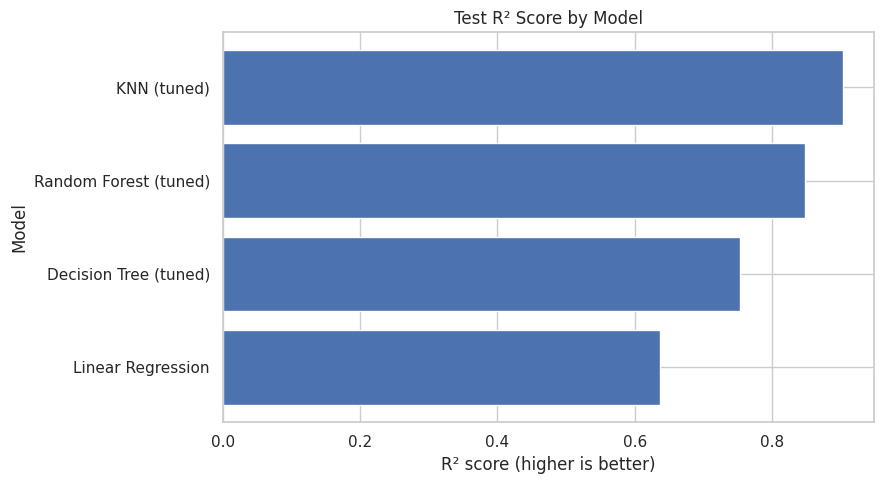

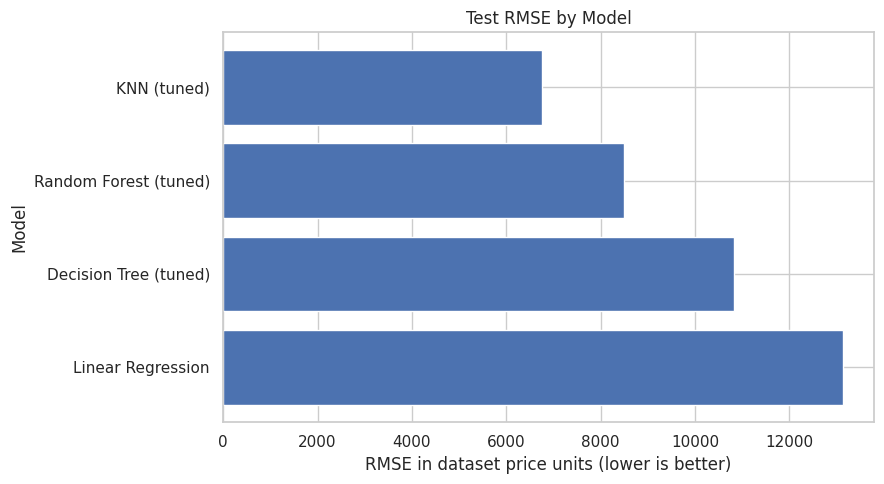

In [26]:
r2_plot = final_results.sort_values("R2", ascending=True)
plt.figure(figsize=(9, 5))
plt.barh(r2_plot["Model"], r2_plot["R2"])
plt.xlabel("R² score (higher is better)")
plt.ylabel("Model")
plt.title("Test R² Score by Model")
plt.tight_layout()
plt.show()

rmse_plot = final_results.sort_values("RMSE", ascending=False)
plt.figure(figsize=(9, 5))
plt.barh(rmse_plot["Model"], rmse_plot["RMSE"])
plt.xlabel("RMSE in dataset price units (lower is better)")
plt.ylabel("Model")
plt.title("Test RMSE by Model")
plt.tight_layout()
plt.show()

## Step 13 — Select the final model using cross-validation

We choose the model family with the lowest cross-validation RMSE on the training set. Then we use its fitted version for the final test-set report. This is a more reliable selection rule than simply choosing the highest test R².

In [27]:
# Use the cross-validation scores already calculated during training and tuning.
selection_rows = [{
    "Model": "Linear Regression",
    "CV RMSE": baseline_results.loc[
        baseline_results["Model"] == "Linear Regression", "CV RMSE Mean"
    ].iloc[0]
}]

for _, row in tuning_results.iterrows():
    selection_rows.append({
        "Model": row["Model"] + " (tuned)",
        "CV RMSE": row["Best CV RMSE"]
    })

selection_results = pd.DataFrame(selection_rows).sort_values("CV RMSE")
display(selection_results.round(3))
best_name = selection_results.iloc[0]["Model"]

if best_name == "Linear Regression":
    best_model = models["Linear Regression"]
else:
    simple_name = best_name.replace(" (tuned)", "")
    best_model = best_tuned_models[simple_name]

best_model.fit(X_train, y_train)
print("Selected final model:", best_name)

,Model,CV RMSE
1,Random Forest (tuned),9379.834
2,KNN Regressor (tuned),10736.583
3,Decision Tree (tuned),11163.205
0,Linear Regression,16831.785


Selected final model: Random Forest (tuned)


## Step 14 — Final evaluation of the selected model

These are the final metrics for the selected model on the held-out test set.

In [28]:
best_test_predictions = best_model.predict(X_test)
best_metrics = calculate_metrics(y_test, best_test_predictions)

print("Final model:", best_name)
print(f"MAE:  {best_metrics['MAE']:.2f}")
print(f"RMSE: {best_metrics['RMSE']:.2f}")
print(f"R²:   {best_metrics['R2']:.4f}")

Final model: Random Forest (tuned)
MAE:  2880.51
RMSE: 8503.63
R²:   0.8477


## Step 15 — Plot actual prices against predicted prices

Points closer to the diagonal line mean the predictions are closer to the actual prices.

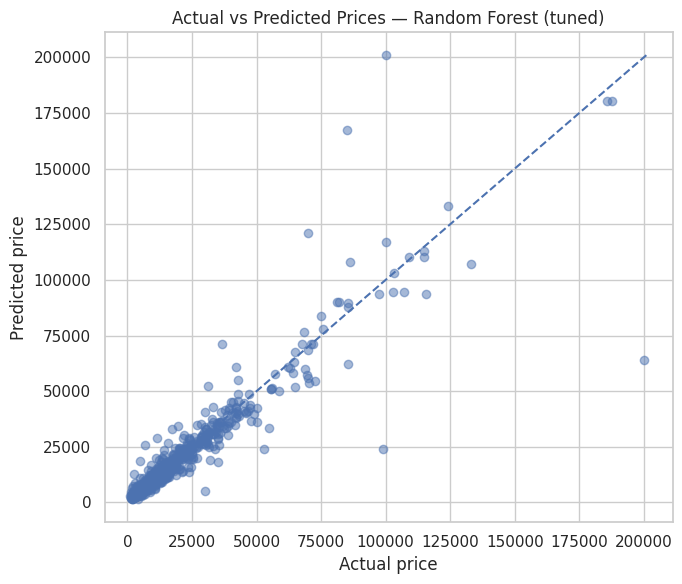

In [29]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_test_predictions, alpha=0.5)
minimum = min(y_test.min(), best_test_predictions.min())
maximum = max(y_test.max(), best_test_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"Actual vs Predicted Prices — {best_name}")
plt.tight_layout()
plt.show()

## Step 16 — Look at prediction errors (residuals)

A residual is actual price minus predicted price. A large residual means the prediction was far from the actual value.

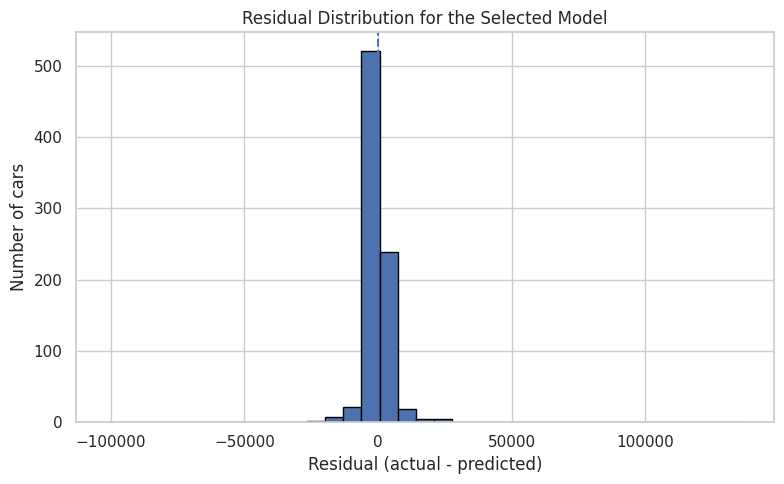

In [30]:
residuals = y_test.to_numpy() - best_test_predictions

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=35, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Number of cars")
plt.title("Residual Distribution for the Selected Model")
plt.tight_layout()
plt.show()

## Step 17 — Save results and the trained model

The saved pipeline includes preprocessing and the model, so the same steps can be reused later. Frontend development is intentionally not included in this stage.

In [31]:
output_folder = Path("artifacts")
output_folder.mkdir(exist_ok=True)

final_results.to_csv(output_folder / "Model_Comparison_Results.csv", index=False)
selection_results.to_csv(output_folder / "Model_CV_Selection.csv", index=False)

prediction_table = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": best_test_predictions,
    "Residual": residuals
})
prediction_table.to_csv(output_folder / "Best_Model_Test_Predictions.csv", index=False)

joblib.dump(best_model, output_folder / "best_used_car_price_pipeline.joblib")

print("Saved comparison results, predictions and final model in:", output_folder)

Saved comparison results, predictions and final model in: artifacts


In [32]:
from google.colab import files

files.download("artifacts/best_used_car_price_pipeline.joblib")
files.download("artifacts/Model_Comparison_Results.csv")
files.download("artifacts/Model_CV_Selection.csv")
files.download("artifacts/Best_Model_Test_Predictions.csv")
files.download("Car_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>